# 02 · Manifold — principal-curve trajectory (embryonic lobe)

Kürten's malignant manifold is **non-branching**: the embryonic-program lobe is an
elongated strip, not a hub radiating to discrete subtypes. The correct topology is
therefore a **principal curve** (ElPiGraph, non-branching by construction) fit on
the *joint* embedding restricted to the embryonic lobe — **not** a re-embedding of
the lobe (an elongated compartment is honest 1-D geometry; re-embedding an
anisotropic strip fabricates folds). The curve is rooted at the
gastrulation/somitogenesis-high tip (the developmental origin), pseudotime flows
to the neural-crest terminus, and the embedding is reoriented to house style
(low pseudotime left → high right). Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and restrict to the embryonic lobe
We keep the cells on their *original joint embedding coordinates* — no re-embedding.

embryonic lobe: 5955 cells on the joint embedding
UMAP strip aspect ratio (major/minor std): 1.63  (elongated -> 1-D geometry)


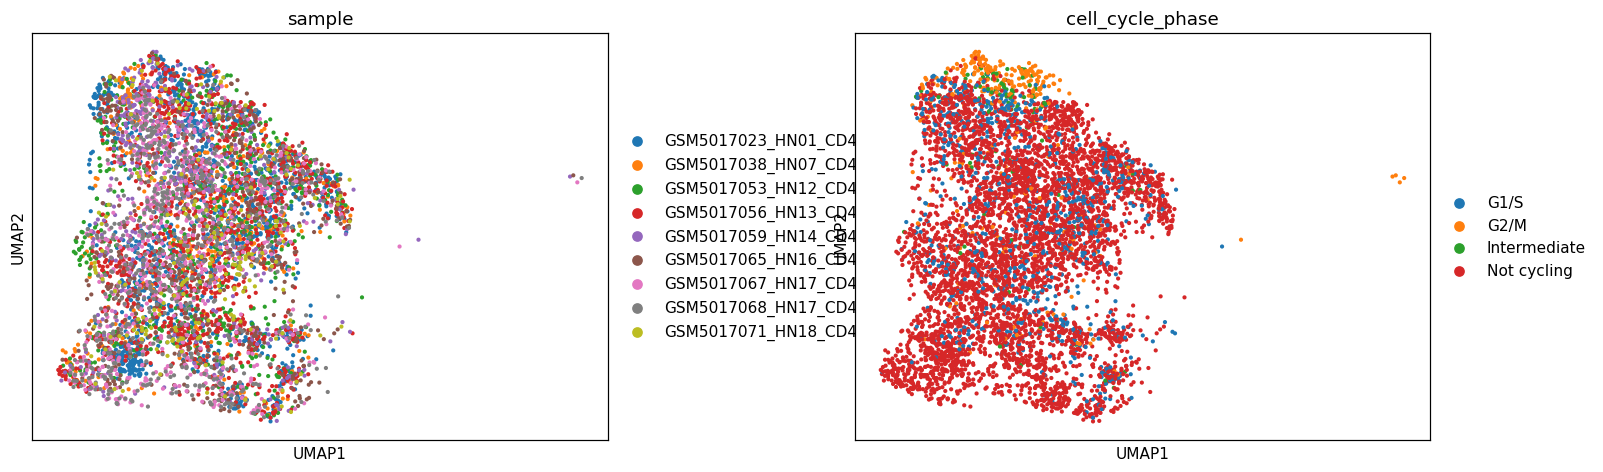

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
sub = adata[adata.obs['compartment']=='Embryonic'].copy()
print('embryonic lobe:', sub.shape[0], 'cells on the joint embedding')
xy = sub.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP strip aspect ratio (major/minor std): {s[0]/s[1]:.2f}  (elongated -> 1-D geometry)')
fig = sc.pl.umap(sub, color=['sample','cell_cycle_phase'], size=30, wspace=.3, show=False)

### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` were tuned to give a **fold-free** monotone backbone: a
node self-approach ratio > 1 (minimum distance between graph-non-adjacent nodes,
in units of median edge length) certifies the curve does not fold back on itself.
`epg_mu=100` is strong bending regularisation (ElPiGraph: `epg_lambda` penalises
stretching, `epg_mu` penalises bending) — it keeps the crescent a smooth
arc rather than a sharp V that would assign near-neighbour cells divergent
pseudotime across the inflection.

In [4]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.89 (>1 = fold-free)


### Score embryonic modules and derive the root (data-driven)
The three developmental signatures (Gastrulation / Somitogenesis / Neural-crest)
are scored against the shared control gene pool, then graph-smoothed to read
*geography* rather than single-cell dropout. The root is set to the curve tip
where Gast+pSom is highest and Crest lowest — the developmental origin.

In [5]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(sub.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(sub.var_names)]
    sc.tl.score_genes(sub, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
# graph-smooth for geography
A = (sub.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = sub.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): sub.obs[lab+'_sm'] = S[:,j]

Gast: 76/81 genes present
pSom: 93/98 genes present
Crest: 101/104 genes present


In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for t in tps:
    m = np.isin(hard, np.where(D[t]<=3)[0])
    info[t] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {t}: Gast={info[t][0]:+.4f} pSom={info[t][1]:+.4f} Crest={info[t][2]:+.4f}')
root = int(max(tps, key=lambda t: info[t][0]+info[t][1]-info[t][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=+0.0208 pSom=+0.0463 Crest=-0.0042
tip 2: Gast=+0.0015 pSom=+0.0289 Crest=+0.0108
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho):
  Gast_sm: rho=-0.323 p=1.1e-144
  pSom_sm: rho=-0.383 p=7.5e-208
  Crest_sm: rho=+0.438 p=4.7e-277


### Reorient to house style (pseudotime left → right)
Orient the linear-trajectory panel using only raw UMAP coordinates with a discrete
dimension swap and axis flip (no rotation/interpolation - those are brittle: an SVD
basis can be a reflection and silently flip an axis). The trajectory's major axis is
near-vertical in the raw embedding, so swapping x<->y makes it horizontal; a single
y-flip gives X_umap_lin = (raw_y, -raw_x). This fixed transform is applied identically
in every deliverable notebook, so all panels share one orientation. The assertion
confirms low pseudotime lands on the left (increasing to the right).

In [7]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
xyr = np.column_stack([xy[:,1], -xy[:,0]])        # swap x<->y, flip y  (no rotation)
r = float(np.corrcoef(xyr[:,0], t)[0,1])
assert r > 0, f'pseudotime not left->right (corr={r:+.2f}); flip x for this dataset'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: swap x<->y + y-flip (no rotation); corr(x_lin, pseudotime) = {r:+.2f}')

orientation: swap x<->y + y-flip (no rotation); corr(x_lin, pseudotime) = +0.99


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


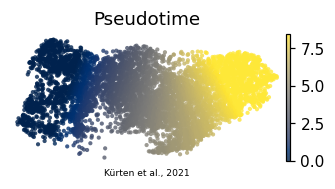

In [8]:
# sanitize non-serializable ElPiGraph uns entry (node positions kept; graph lives in uns['graph'])
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Kürten et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')